# Trafego aereo no corredor São Paulo-Rio

Análise de dados ADS-B coletados da OpenSky Network entre 10 e 25 de outubro de 2026, em intervalos de 60 segundos, sobre uma área que cobre o Vale do Paraíba e as aproximações de São Paulo e Rio de Janeiro.

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

import config

## 1. Carga
Os arquivos são lidos da pasta 'dados/', um por dia de coleta, e empilhados num único DataFrame.

In [28]:
arquivos = sorted(config.PASTA_DADOS.glob("estados_*.csv"))
df = pd.concat(
    (pd.read_csv(a, on_bad_lines="skip") for a in arquivos),
    ignore_index=True,  
)

print(f"{len(arquivos)} arquivos | {len(df):,} registros")

16 arquivos | 728,105 registros


## 2. Tratamento
Três transformações: conversão de tempo para horario local, classificacao do tipo de operacao pelo formato do callsign, e descarte dos dias parciais das pontas.

In [29]:
# --- Tempo ---
df["ts_consulta"] = pd.to_datetime(df["ts_consulta"], utc=True)
df["ts_local"] = df["ts_consulta"].dt.tz_convert("America/Sao_Paulo")

df["data"] = df["ts_local"].dt.date
df["hora"] = df["ts_local"].dt.hour
df["dia_semana"] = df["ts_local"].dt.dayofweek  # 0 = segunda

# --- Tipo de operação ---
df["callsign"] = df ["callsign"].fillna("").str.strip()

def classificar(cs):
    if cs == "":
        return "sem identificacao"
    if cs.startswith("EMB"):
        return "Embraer"
    if len(cs) >= 4 and cs[:3].isalpha() and cs[3].isdigit():
        return "companhia"
    return "matricula"

df["tipo_operacao"] = df["callsign"].map(classificar)

# --- Dias completos ---
dias = sorted(df["data"].unique())
dias_completos = dias[1:-1]
dfc_bruto = df[df["data"].isin(dias_completos)].copy()

# --- Horas completas ---
ciclos_hora = dfc_bruto.groupby(["data", "hora"])["ts_consulta"].nunique()
dfc_bruto["ciclos_hora"] = dfc_bruto.set_index(["data", "hora"]).index.map(ciclos_hora)
dfc = dfc_bruto[dfc_bruto["ciclos_hora"] >= 55]

print(f"Dias completos   : {len(dias_completos)} ({dias_completos[0]} a {dias_completos[-1]})")
print(f"Horas descartadas: {(ciclos_hora < 55).sum()} de {len(ciclos_hora)}")
print(f"Registros usáveis: {len(dfc):,}")
print(f"Aeronaves únicas : {dfc['icao24'].nunique():,}")
print()
print(dfc["tipo_operacao"].value_counts().to_string())
print(f"Category utilizavel: {dfc['category'].isin(range(2, 21)).mean() * 100:.2f}%")



Dias completos   : 14 (2026-10-11 a 2026-10-24)
Horas descartadas: 5 de 336
Registros usáveis: 713,767
Aeronaves únicas : 2,684

tipo_operacao
companhia            566924
matricula            128337
sem identificacao     18275
Embraer                 231
Category utilizavel: 0.39%


## 3. Ritmo diário
Aeronaves distintas observadas por hora do dia.A linha é media entre os dias completos; a faixa mostra o minimo e o maximo observados em cada hora.

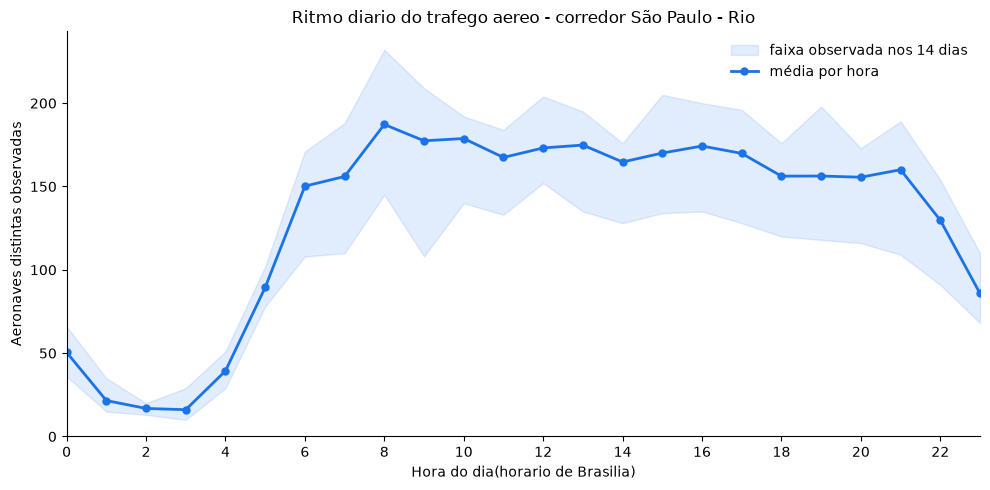

       mean  min  max
hora                 
0      50.5   36   66
1      21.6   15   35
2      16.8   13   20
3      16.1   10   29
4      39.4   29   51
5      89.4   78  102
6     150.2  108  171
7     156.0  110  188
8     187.2  145  232
9     177.4  108  209
10    178.8  140  192
11    167.4  133  184
12    173.1  152  204
13    174.9  135  195
14    164.7  128  176
15    170.1  134  205
16    174.3  135  200
17    169.9  128  196
18    156.2  120  176
19    156.3  118  198
20    155.6  116  173
21    160.1  109  189
22    129.8   91  154
23     85.9   68  110


In [ ]:
from pathlib import Path

PASTA_GRAFICOS = Path("graficos")
PASTA_GRAFICOS.mkdir(exist_ok=True)

por_hora_dia = (
    dfc.groupby(["data", "hora"])["icao24"]
    .nunique()
    .reset_index(name="aeronaves")
)

resumo = por_hora_dia.groupby("hora")["aeronaves"].agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(10, 5))

ax.fill_between(
    resumo.index, resumo["min"], resumo["max"],
    color="#8ab4f8", alpha=0.25,
    label=f"faixa observada nos {len(dias_completos)} dias",
)
ax.plot(
    resumo.index, resumo["mean"],
    color="#1a73e8", linewidth=2, marker="o", markersize=5,
    label="média por hora",
)
ax.legend()
ax.set_title("Ritmo diário do trafego aéreo - corredor São Paulo - Rio")
ax.set_xlabel("Hora do dia(horário de Brasilia)")
ax.set_ylabel("Aeronaves distintas observadas")
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(0, 23)
ax.set_ylim(bottom=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(PASTA_GRAFICOS / "p1_curva_24h.png", dpi=150)
plt.show()

print(resumo.round(1).to_string())



## 4. Dia útil x fim de semana

Mesma métrica da seção anterior, separando os 10 dias úteis dos 4 dias de fim de semana.A comparação é feita sobre médias, já que os grupos têm tamanhos diferentes.

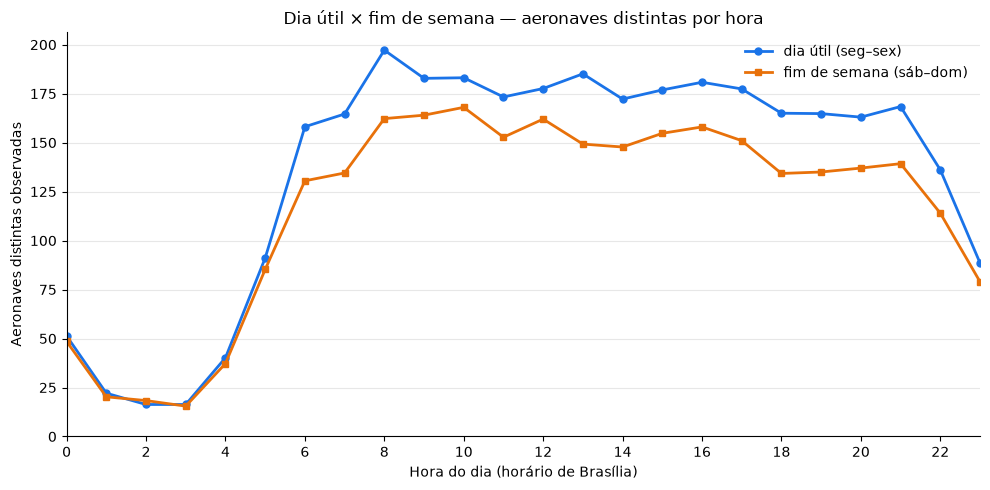

Dias úteis: 10 | Fins de semana: 4
Diferença média ao longo do dia: +18.9 aeronaves
Maior diferença: +35.8 às 13h


In [31]:
# Refaz o agrupamento carregando o dia da semana junto
por_hora_dia = (
    dfc.groupby(["data", "dia_semana", "hora"])["icao24"]
       .nunique()
       .reset_index(name="aeronaves")
)

por_hora_dia["grupo"] = por_hora_dia["dia_semana"].map(
    lambda d: "fim de semana" if d >= 5 else "dia util"
)

media = por_hora_dia.groupby(["grupo", "hora"])["aeronaves"].mean()
util = media.loc["dia util"]
fds = media.loc["fim de semana"]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(util.index, util.values, color="#1a73e8", linewidth=2,
        marker="o", markersize=5, label="dia útil (seg–sex)")
ax.plot(fds.index, fds.values, color="#e8710a", linewidth=2,
        marker="s", markersize=5, label="fim de semana (sáb–dom)")

ax.set_title("Dia útil × fim de semana — aeronaves distintas por hora")
ax.set_xlabel("Hora do dia (horário de Brasília)")
ax.set_ylabel("Aeronaves distintas observadas")
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(0, 23)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(PASTA_GRAFICOS / "p1_util_vs_fds.png", dpi=150)
plt.show()

dif = util - fds
n_util = por_hora_dia[por_hora_dia["grupo"] == "dia util"]["data"].nunique()
n_fds = por_hora_dia[por_hora_dia["grupo"] == "fim de semana"]["data"].nunique()

print(f"Dias úteis: {n_util} | Fins de semana: {n_fds}")
print(f"Diferença média ao longo do dia: {dif.mean():+.1f} aeronaves")
print(f"Maior diferença: {dif.max():+.1f} às {dif.idxmax()}h")

## 5. Qualidade e limitações do dado

Verificação da própria coleta: onde houve falhas, e se as anomalias visíveis nos
gráficos são efeito real ou artefato de coleta incompleta.

In [32]:
# Os cinco dias com menos aeronaves às 14h
h14 = por_hora_dia[por_hora_dia["hora"] == 14].sort_values("aeronaves")
print("Dias com menor movimento às 14h:")
print(h14.head(5)[["data", "aeronaves"]].to_string(index=False))

# Horas em que a coleta não completou os 60 ciclos esperados
ciclos = dfc.groupby(["data", "hora"])["ts_consulta"].nunique()
incompletas = ciclos[ciclos < 55]

print(f"\nHoras com coleta incompleta: {len(incompletas)}")
print(incompletas.to_string())

Dias com menor movimento às 14h:
      data  aeronaves
2026-10-11        128
2026-10-24        139
2026-10-17        150
2026-10-15        164
2026-10-20        169

Horas com coleta incompleta: 0
Series([], )


## 6. Distribuição geográfica

Densidade de posições registradas ao longo dos 14 dias. Cada célula do mapa conta
quantas posições caíram ali. A escala é logarítmica, porque a densidade entre as
rotas principais e as áreas vazias varia em várias ordens de grandeza.

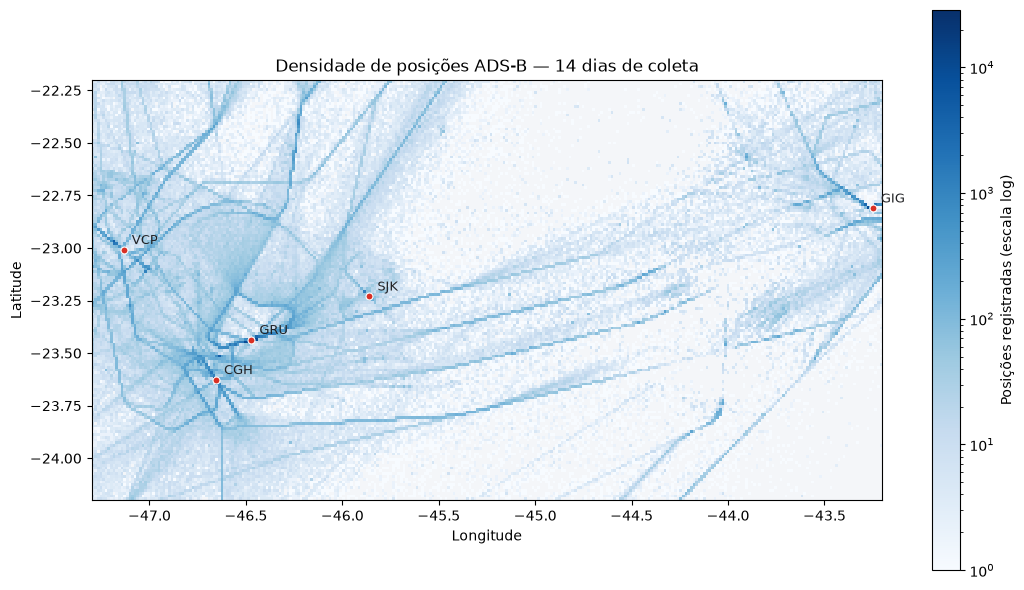

Posições plotadas: 713,767


In [33]:
from matplotlib.colors import LogNorm

pos = dfc.dropna(subset=["latitude", "longitude"])

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_facecolor("#f4f6f9")

h = ax.hist2d(
    pos["longitude"], pos["latitude"],
    bins=(300, 150),
    range=[[config.CAIXA["lomin"], config.CAIXA["lomax"]],
           [config.CAIXA["lamin"], config.CAIXA["lamax"]]],
    cmap="Blues",
    norm=LogNorm(),
)

aeroportos = {
    "VCP": (-47.1345, -23.0074),
    "GRU": (-46.4731, -23.4356),
    "CGH": (-46.6564, -23.6261),
    "SJK": (-45.8613, -23.2287),
    "GIG": (-43.2506, -22.8099),
}

for nome, (lon, lat) in aeroportos.items():
    ax.plot(lon, lat, marker="o", markersize=5, color="#d93025",
            markeredgecolor="white", markeredgewidth=0.8, zorder=5)
    ax.annotate(nome, (lon, lat), xytext=(6, 4), textcoords="offset points",
                fontsize=9, color="#202124", zorder=6)

ax.set_aspect(1.09)
ax.set_title("Densidade de posições ADS-B — 14 dias de coleta")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

cbar = fig.colorbar(h[3], ax=ax)
cbar.set_label("Posições registradas (escala log)")

fig.tight_layout()
fig.savefig(PASTA_GRAFICOS / "p2_mapa_densidade.png", dpi=150)
plt.show()

print(f"Posições plotadas: {len(pos):,}")